In [27]:
#importing libraries
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
 
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [28]:
#getting data

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)
 
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [29]:
#data preperation
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed',
             'interaction_count', 'lead_score']
 
print('Missing values per column:')
print(df.isnull().sum())
 
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
 
# Split (exact calls from the homework, random_state=1 this time)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
 
y_train = df_train.converted.values
y_val = df_val.converted.values
 
del df_train['converted']
del df_val['converted']
del df_test['converted']

Missing values per column:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [30]:
#question 1
q1 = {}
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    q1[col] = auc
    print(f'{col:28s} {auc:.4f}')
print('Highest AUC:', max(q1, key=q1.get))

annual_income                0.6082
number_of_courses_viewed     0.7230
interaction_count            0.7649
lead_score                   0.7882
Highest AUC: lead_score


In [31]:
#train / predict with one-hot encoding
features = categorical + numerical
 
 
def train(df_tr, y_tr, C=1.0):
    dicts = df_tr[features].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model
 
 
def predict(df_in, dv, model):
    X = dv.transform(df_in[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

In [32]:
#question 2
dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
print('\nQ2: validation AUC =', round(roc_auc_score(y_val, y_pred), 3))


Q2: validation AUC = 0.732


In [33]:
#question 3
rows = []
for t in np.arange(0.0, 1.01, 0.01):
    predict_pos = (y_pred >= t)
    predict_neg = (y_pred < t)
    actual_pos = (y_val == 1)
 
    tp = (predict_pos & actual_pos).sum()
    fp = (predict_pos & ~actual_pos).sum()
    fn = (predict_neg & actual_pos).sum()
 
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    rows.append((round(t, 2), p, r))
 



Q3: curves intersect at threshold = 0.63 (precision=0.7328, recall=0.7253)


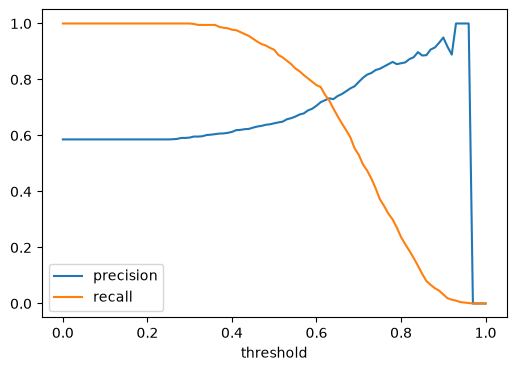

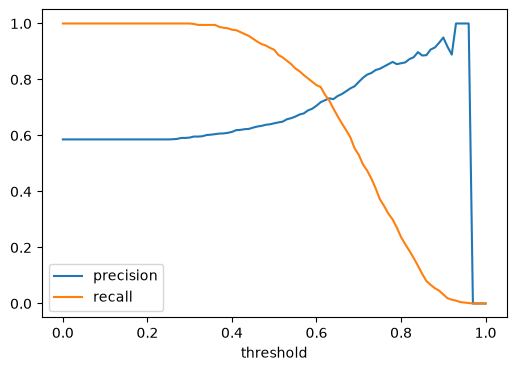

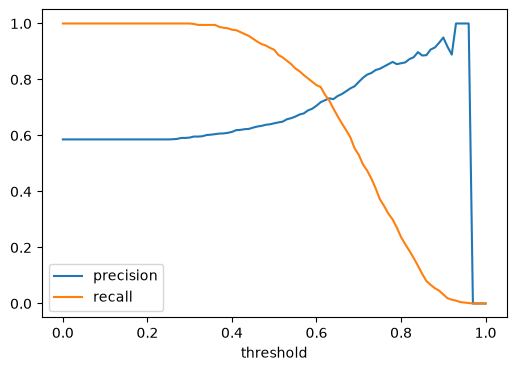

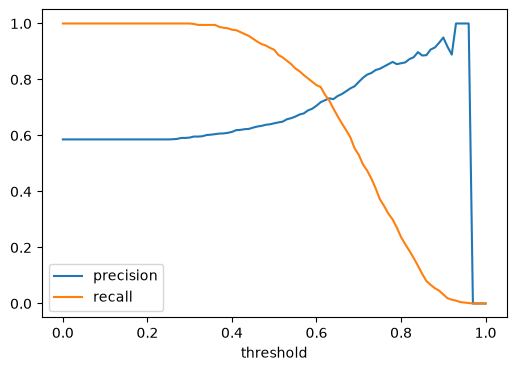

In [34]:
scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall'])
 
plt.figure(figsize=(6, 4))
plt.plot(scores.threshold, scores.precision, label='precision')
plt.plot(scores.threshold, scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.savefig('precision_recall.png', dpi=120, bbox_inches='tight')
 
valid = scores[(scores.precision > 0) | (scores.recall > 0)].copy()
valid['abs_diff'] = (valid.precision - valid.recall).abs()
q3 = valid.loc[valid.abs_diff.idxmin()]
print('\nQ3: curves intersect at threshold =', q3.threshold,
      f'(precision={q3.precision:.4f}, recall={q3.recall:.4f})')

In [35]:
#question 4
denom = scores.precision + scores.recall
scores['f1'] = np.where(denom > 0,
                        2 * scores.precision * scores.recall / denom, 0.0)
best = scores.loc[scores.f1.idxmax()]
print('\nQ4: max F1 =', round(best.f1, 4), 'at threshold', best.threshold)


Q4: max F1 = 0.7576 at threshold 0.41


In [36]:
#question 5
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
aucs = []
for train_idx, val_idx in kfold.split(df_full_train):
    fold_train = df_full_train.iloc[train_idx]
    fold_val = df_full_train.iloc[val_idx]
 
    dv_f, model_f = train(fold_train, fold_train.converted.values)
    pred_f = predict(fold_val, dv_f, model_f)
    aucs.append(roc_auc_score(fold_val.converted.values, pred_f))
 
print('\nQ5: fold AUCs =', np.round(aucs, 4))
print('    std =', round(np.std(aucs), 3))


Q5: fold AUCs = [0.7306 0.7296 0.7363 0.7412 0.7209]
    std = 0.007


In [37]:
#question 6
results = {}
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    fold_aucs = []
    for train_idx, val_idx in kfold.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]
 
        dv_f, model_f = train(fold_train, fold_train.converted.values, C=C)
        pred_f = predict(fold_val, dv_f, model_f)
        fold_aucs.append(roc_auc_score(fold_val.converted.values, pred_f))
 
    results[C] = (round(np.mean(fold_aucs), 3), round(np.std(fold_aucs), 3))
    print(f'C={C}: mean={results[C][0]}, std={results[C][1]}')
 
# best mean; ties -> lowest std; still tied -> smallest C
best_C = min(results, key=lambda c: (-results[c][0], results[c][1], c))
print('Best C:', best_C)


C=1e-06: mean=0.617, std=0.019
C=0.001: mean=0.749, std=0.01
C=1: mean=0.732, std=0.007
Best C: 0.001
